# Notebook 04 — Statistical Analysis


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

BASE_DIR = Path.cwd()
if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

PROCESSED_DIR = BASE_DIR / "data" / "processed"
df = pd.read_csv(PROCESSED_DIR / "IPL_Batting_Statistics_Cleaned.csv")
innings_df = pd.read_csv(PROCESSED_DIR / "IPL_Batting_Innings_Cleaned.csv")
from scipy import stats


In [2]:
correlation_data = df[["Runs", "Strike_Rate"]].dropna()

pearson = stats.pearsonr(correlation_data["Runs"], correlation_data["Strike_Rate"])
spearman = stats.spearmanr(correlation_data["Runs"], correlation_data["Strike_Rate"])

correlation_results = pd.DataFrame({
    "Method": ["Pearson", "Spearman"],
    "Correlation": [pearson.statistic, spearman.statistic],
    "P_Value": [pearson.pvalue, spearman.pvalue],
})

display(correlation_results.round(4))


,Method,Correlation,P_Value
0,Pearson,0.4217,0.0
1,Spearman,0.6654,0.0


In [3]:
metrics = [
    "Runs", "Batting_Average", "Strike_Rate",
    "Fours", "Sixes", "Dot_Ball_Percentage",
]
correlation_matrix = df[metrics].corr()
display(correlation_matrix.round(4))


,Runs,Batting_Average,Strike_Rate,Fours,Sixes,Dot_Ball_Percentage
Runs,1.0000,0.7250,0.4217,0.9667,0.8857,-0.3116
Batting_Average,0.7250,1.0000,0.6218,0.6671,0.6703,-0.5641
Strike_Rate,0.4217,0.6218,1.0000,0.3855,0.4711,-0.7391
Fours,0.9667,0.6671,0.3855,1.0000,0.7848,-0.2689
Sixes,0.8857,0.6703,0.4711,0.7848,1.0000,-0.2808
Dot_Ball_Percentage,-0.3116,-0.5641,-0.7391,-0.2689,-0.2808,1.0000


In [4]:
print("Runs vs Strike_Rate — Pearson r:", round(pearson.statistic, 4))
print("Runs vs Strike_Rate — Spearman rho:", round(spearman.statistic, 4))
print("Sample size:", len(correlation_data))


Runs vs Strike_Rate — Pearson r: 0.4217
Runs vs Strike_Rate — Spearman rho: 0.6654
Sample size: 2857


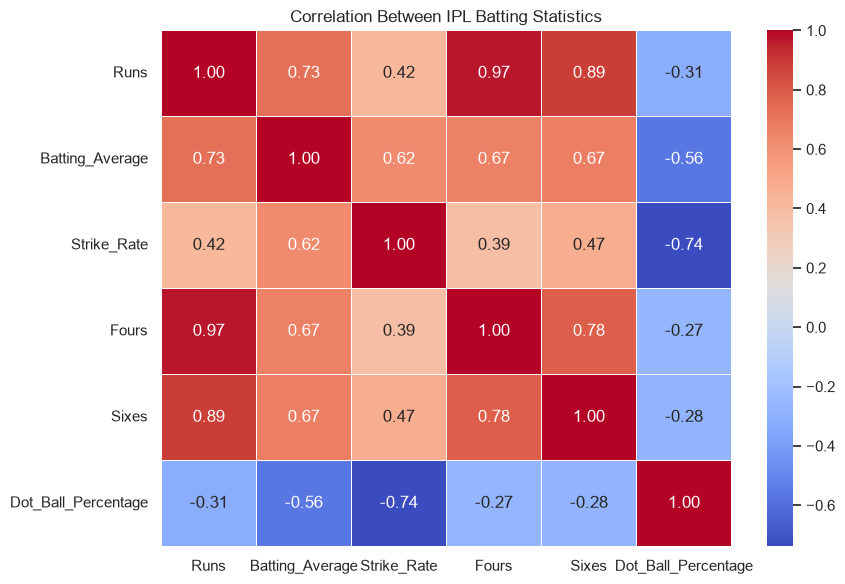

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

BASE_DIR = Path.cwd()
if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent
FIGURE_DIR = BASE_DIR / "outputs" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(9, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Between IPL Batting Statistics")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "batting_correlation_heatmap_stats.png", dpi=300)
plt.show()
